# EEG Reader
## What does this notebook do?

1. Taking in an .xdf file and reading its values. (including getting the files from another source)
2. Display the signal data including its markers visually.
3. Format the data correctly for a common table/dataset approach, including
  - Removing the 5s pause in between
  - Assign the respective snippets to their genre
  - Create a folder for that, specifying the session number this was
  - (Maybe) convert to MNE format for easier preprocessing

In [1]:
# Important constants
SESSION_NUMBER = 0

## Example usage from https://github.com/xdf-modules/pyxdf

Marker "00005" @ 10503.623963220003s
Marker "00007" @ 10539.735893170904s
Marker "00006" @ 10574.921609630757s
Marker "00007" @ 10610.84620358347s
Marker "00008" @ 10646.530477538505s
Marker "00006" @ 10681.745348598079s
Marker "00009" @ 10717.287696054485s
Marker "00007" @ 10753.017816109075s
Marker "00006" @ 10788.72700016387s
Marker "00009" @ 10823.950777923357s
Marker "Start Recording" @ 10503.623703636642s
Marker "End Recording" @ 10534.731181675992s
Marker "Start Recording" @ 10539.735258701892s
Marker "End Recording" @ 10569.91776985494s
Marker "Start Recording" @ 10574.920790480854s
Marker "End Recording" @ 10605.842475122956s
Marker "Start Recording" @ 10610.845675948867s
Marker "End Recording" @ 10641.526202094541s
Marker "Start Recording" @ 10646.52948942045s
Marker "End Recording" @ 10676.740961273072s
Marker "Start Recording" @ 10681.744398798977s
Marker "End Recording" @ 10712.284542246733s
Marker "Start Recording" @ 10717.28728457265s
Marker "End Recording" @ 10748.01435

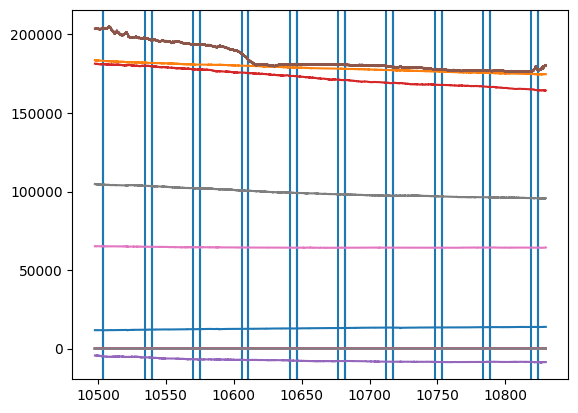

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pyxdf

# Test
data, header = pyxdf.load_xdf("sub-P001_ses-S001_task-Default_run-001_eeg.xdf")

for stream in data:
    y = stream["time_series"]

    if isinstance(y, list):
        # list of strings, draw one vertical line for each marker
        for timestamp, marker in zip(stream["time_stamps"], y):
            plt.axvline(x=timestamp)
            print(f'Marker "{marker[0]}" @ {timestamp}s')
    elif isinstance(y, np.ndarray):
        # numeric data, draw as lines
        plt.plot(stream["time_stamps"], y)
    else:
        raise RuntimeError("Unknown stream format")

plt.show()